# EXAMEN PARCIAL — DATA MINING


Docente: Soledad Espezúa Llerena

## Instrucciones
- Coloque su nombre completo al inicio del cuadernillo.
- Renombre el archivo siguiendo la estructura: `EP_DM_PrimerNombre_PrimerApellido.ipynb`.
- Muestre evidencia de los procedimientos realizados. No se calificará únicamente el resultado final si no se presenta el código que lo produce.
- Para la preparación y análisis de los datos puede utilizar `pandas`.
- Para las visualizaciones utilice **Seaborn y/o Plotly**, de acuerdo con lo trabajado en el curso.




---



Nombre alumno:

Arturo Alvarez de la Torre Sequeiros
---



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler

clientes = pd.read_csv("clientes.csv")
compras = pd.read_csv("compras.csv")

print("clientes:", clientes.shape)
print("compras:", compras.shape)
display(clientes.head())
display(compras.head())

clientes: (121, 5)
compras: (520, 6)


,cliente_id,edad,distrito,tipo_cliente,ingreso_mensual
0,C001,29,San Isidro,Básico,1416.0
1,C002,38,La Molina,Básico,2882.0
2,C003,21,Surco,Regular,3735.0
3,C004,32,San Isidro,Regular,5852.0
4,C005,47,Surco,Básico,NaN


,compra_id,cliente_id,fecha,monto_compra,categoria,descuento_pct
0,V0001,C001,2026-08-16,217.02,Alimentos,0.0
1,V0002,C001,2026-07-04,15.00,Moda,10.0
2,V0003,C001,2026-08-02,86.13,Hogar,10.0
3,V0004,C001,2026-07-14,340.17,Deportes,0.0
4,V0005,C002,2026-01-28,122.34,Hogar,5.0


# <font color=green> Parte 1: Calidad y limpieza [4 puntos]</font>
#### 1. [1.5 puntos] Identificacion de al menos **tres problemas de calidad de datos** presentes.

In [3]:
clientes.describe()

,edad,ingreso_mensual
count,121.000000,109.000000
mean,38.942149,4125.504587
std,14.647126,1879.211614
min,18.000000,1200.000000
25%,31.000000,2801.000000
50%,38.000000,3826.000000
75%,46.000000,5136.000000
max,145.000000,8924.000000


In [4]:
for i in compras["monto_compra"]:
    if i <0:
        print(i)
        print("Hay al menos un valor negativo en monto_compra")
            

-150.0
Hay al menos un valor negativo en monto_compra


In [5]:
# Escriba aquí su solución
clientes["edad"].unique()


array([ 29,  38,  21,  32,  47,  19,  45,  35,  26,  53,  48,  22,  30,
        37,  52,  34,  44,  36,  42,  49,  40,  25,  23,  46,  33,  20,
       145,  24,  18,  60,  39,  43,  41,  50,  63,  31,  51,  62,  54,
        27,  56,  55,  67])

Hay una edad de años 145 años 

In [6]:
clientes["cliente_id"].is_unique


False

In [7]:
for i in range(110,121):
    print(clientes["cliente_id"][i])

C111
C112
C113
C114
C115
C116
C117
C118
C119
C120
C045


Hay al menos un duplicado en los ids de clientes, está al final
Se duplica el id C045

In [8]:
compras["compra_id"].is_unique

True

#### 2. [2.5 puntos] Realice las correcciones

In [64]:
#Corrigiendo el de duplicado
clientes

<bound method Series.drop_duplicates of 0      C001
1      C002
2      C003
3      C004
4      C005
       ... 
116    C117
117    C118
118    C119
119    C120
120    C045
Name: cliente_id, Length: 121, dtype: object>

In [57]:
clientes["cliente_id"][120]

'C045'

In [9]:
# Escriba aquí su solución
print("Antes:", clientes.shape)
clientes = clientes.drop_duplicates()           
print("Después:", clientes.shape)

Antes: (121, 5)
Después: (120, 5)



# <font color=green> Parte 2: Valores faltantes y valores atípicos [4 puntos]</font>
#### 3. [2 puntos] Valores faltantes



**a) [1 punto]** Determine cuántos valores faltantes existen y su porcentaje.  


In [52]:
# Escriba aquí su solución
print("Valores faltantes en fuente 1:")
display(clientes.isnull().sum())

print("Valores faltantes en fuente 2:")
display(compras.isnull().sum())

Valores faltantes en fuente 1:


cliente_id          0
edad                0
distrito            0
tipo_cliente        0
ingreso_mensual    12
dtype: int64

Valores faltantes en fuente 2:


compra_id        0
cliente_id       0
fecha            0
monto_compra     0
categoria        0
descuento_pct    0
dtype: int64

**b) [1 punto]** Implemente una estrategia apropiada de tratamiento para los valores faltantes.

In [ ]:
# Escriba aquí su solución


####4. [2 puntos] Valores atípicos
Función `detectar_outliers_iqr()`  con `factor=3`.



In [11]:
def detectar_outliers_iqr(df, columna, factor=3):
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - factor * iqr
    limite_superior = q3 + factor * iqr

    mascara = (
        (df[columna] < limite_inferior) |
        (df[columna] > limite_superior)
    )

    candidatos = df.loc[mascara].copy()

    print("Variable:", columna)
    print("Límite inferior:", round(limite_inferior, 2))
    print("Límite superior:", round(limite_superior, 2))
    print("Candidatos:", candidatos.shape[0])

    return candidatos, limite_inferior, limite_superior

**a) [0.5 puntos]** Observaciones detectadas e interpretación.


In [12]:
# Escriba aquí su solución
detectar_outliers_iqr(compras, "monto_compra")

Variable: monto_compra
Límite inferior: -289.81
Límite superior: 520.52
Candidatos: 10


(    compra_id cliente_id       fecha  monto_compra   categoria  descuento_pct
 52      V0053       C012  2026-06-08       3200.00  Tecnología            0.0
 157     V0158       C038  2026-01-24        532.94        Moda           10.0
 188     V0189       C042  2026-06-12        643.33        Moda            0.0
 230     V0231       C052  2026-08-22       2450.00   Alimentos            0.0
 323     V0324       C072  2026-08-18        654.11  Tecnología            0.0
 403     V0404       C086  2026-08-23       4100.00    Deportes           15.0
 406     V0407       C087  2026-08-28       5200.00    Deportes           10.0
 426     V0427       C090  2026-07-10        578.50  Tecnología           20.0
 429     V0430       C090  2026-07-30        557.04  Tecnología           10.0
 504     V0505       C105  2026-06-18       6800.00        Moda            0.0,
 np.float64(-289.81499999999994),
 np.float64(520.5224999999999))

**b) [1.5 puntos]** Nueva variable `monto_compra_ajustada`

In [18]:
compras["monto_compra"].quantile(0.75)

np.float64(57.472500000000004)

In [47]:
# Escriba aquí su solución
compras["monto_compra_ajustada"] = compras["monto_compra"]

compras.loc[compras["monto_compra"] < compras["monto_compra"].quantile(0.25)]  = compras["monto_compra"].quantile(0.25)
compras.loc[compras["monto_compra"] > compras["monto_compra"].quantile(0.75)] = compras["monto_compra"].quantile(0.75) 

   

In [50]:
detectar_outliers_iqr(compras,"monto_compra_ajustada")

Variable: monto_compra_ajustada
Límite inferior: -289.37
Límite superior: 520.03
Candidatos: 0


(Empty DataFrame
 Columns: [compra_id, cliente_id, fecha, monto_compra, categoria, descuento_pct, monto_compra_ajustada]
 Index: [],
 np.float64(-289.3696875),
 np.float64(520.03265625))

<Axes: xlabel='monto_compra', ylabel='monto_compra_ajustada'>

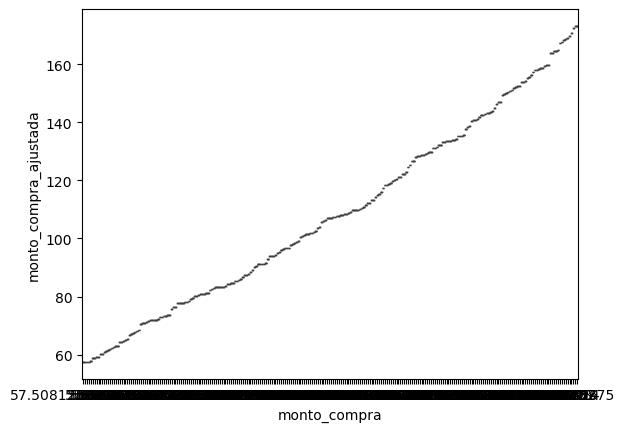

In [56]:

sns.boxplot(
    data=compras,
    x="monto_compra",
    y = "monto_compra_ajustada"
    
)

# <font color=green> Parte 3: Agregación, integración y EDA [5 puntos]</font>

#### 5. [2 puntos] Agregación e integración

**a) [1 punto]** Tabla resumen por `cliente_id`



In [43]:
resumen = (
    compras.groupby(
        "cliente_id",
        observed = False 
    ).agg(
    gasto_total_ajustado = ("monto_compra_ajustada", "sum") ,
    numero_compras = ("monto_compra_ajustada", "size"),
    monto_mediano = ("monto_compra", "median"),
    ultima_compra = ("fecha", "last"), 
    descuento_promedio = ("descuento_pct", "mean")
    ))
resumen

,gasto_total_ajustado,numero_compras,monto_mediano,ultima_compra,descuento_promedio
cliente_id,,,,,
57.4725,7471.425,130,57.4725,57.4725,57.4725
173.235,22520.550,130,173.2350,173.235,173.2350
C001,86.130,1,86.1300,2026-08-02,10.0000
C002,206.080,2,103.0400,2026-03-22,2.5000
C003,500.390,4,120.5850,2026-01-13,8.7500
...,...,...,...,...,...
C105,60.870,1,60.8700,2026-07-29,0.0000
C106,58.900,1,58.9000,2026-06-12,5.0000
C108,84.640,1,84.6400,2026-06-09,15.0000


**b) [1 punto]** Integración de tabla resumen con la base de clientes

In [52]:
# Escriba aquí su solución
base = resumen.merge( 
    clientes, 
    on =  "cliente_id", 
    how = "left"
)
base

,cliente_id,gasto_total_ajustado,numero_compras,monto_mediano,ultima_compra,descuento_promedio,edad,distrito,tipo_cliente,ingreso_mensual
0,57.4725,7471.425,130,57.4725,57.4725,57.4725,NaN,NaN,NaN,NaN
1,173.235,22520.550,130,173.2350,173.235,173.2350,NaN,NaN,NaN,NaN
2,C001,86.130,1,86.1300,2026-08-02,10.0000,29.0,San Isidro,Básico,1416.0
3,C002,206.080,2,103.0400,2026-03-22,2.5000,38.0,La Molina,Básico,2882.0
4,C003,500.390,4,120.5850,2026-01-13,8.7500,21.0,Surco,Regular,3735.0
...,...,...,...,...,...,...,...,...,...,...
96,C105,60.870,1,60.8700,2026-07-29,0.0000,47.0,San Borja,Básico,2161.0
97,C106,58.900,1,58.9000,2026-06-12,5.0000,46.0,Barranco,Regular,3234.0
98,C108,84.640,1,84.6400,2026-06-09,15.0000,32.0,Surco,Básico,1711.0
99,C901,93.830,1,93.8300,2026-04-24,0.0000,NaN,NaN,NaN,NaN


#### 6. [3 puntos] Análisis exploratorio

**a) [2 puntos]** visualización de  `gasto_total_ajustado` entre los distintos `tipo_cliente`.



<Axes: xlabel='gasto_total_ajustado', ylabel='tipo_cliente'>

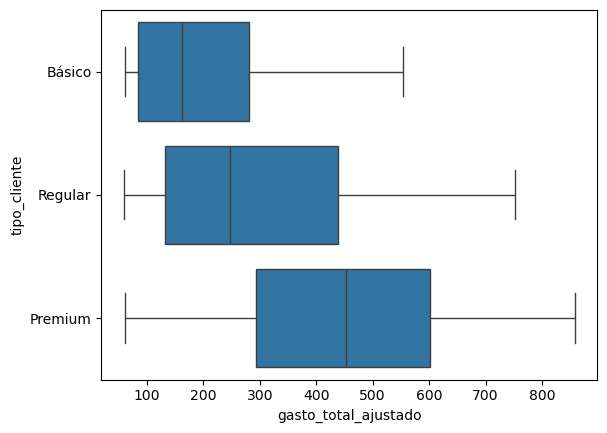

In [74]:
# Escriba aquí su solución

sns.boxplot(
    data=base,
    x="gasto_total_ajustado",
    y = "tipo_cliente"
    
)

Según la visualización, sí existen diferencias entre los tipos de clientes y sus gastos. Debería igual hacerse una prueba de hipótesis estadística para poder determinarlo rigorosamente


**b) [1 punto]** Respuesta a `tipo_cliente`  a priorizar para una promoción

#**Justificación breve:**
Si la promoción es para incrementar el gsto de los clientes con menor nivel de consumo, los de menor consumo son los de tipo de cliente básico, ya que están muy por debajo del resto de categorías, Valdría la pena igual poder ver el impacto de la promoción respecto a cuántos clientes tienen este tipo de cliente.

# <font color=green> Parte 4: Transformación y matriz analítica [5 puntos]</font>

#### 7. [1.5 puntos] Codificación de variables categóricas


Diccionario para construir variable `zona`

In [59]:
mapa_zona = {
    "Los Olivos": "Norte",
    "Independencia": "Norte",
    "Comas": "Norte",
    "Miraflores": "Centro",
    "San Isidro": "Centro",
    "Barranco": "Centro",
    "Surco": "Sur",
    "San Borja": "Sur",
    "La Molina": "Sur"
}

In [67]:
# Escriba aquí su solución
base["distrito"] = (
    base["distrito"]
    .map(mapa_zona))
base

,cliente_id,gasto_total_ajustado,numero_compras,monto_mediano,ultima_compra,descuento_promedio,edad,distrito,tipo_cliente,ingreso_mensual
0,57.4725,7471.425,130,57.4725,57.4725,57.4725,NaN,NaN,NaN,NaN
1,173.235,22520.550,130,173.2350,173.235,173.2350,NaN,NaN,NaN,NaN
2,C001,86.130,1,86.1300,2026-08-02,10.0000,29.0,NaN,Básico,1416.0
3,C002,206.080,2,103.0400,2026-03-22,2.5000,38.0,NaN,Básico,2882.0
4,C003,500.390,4,120.5850,2026-01-13,8.7500,21.0,NaN,Regular,3735.0
...,...,...,...,...,...,...,...,...,...,...
96,C105,60.870,1,60.8700,2026-07-29,0.0000,47.0,NaN,Básico,2161.0
97,C106,58.900,1,58.9000,2026-06-12,5.0000,46.0,NaN,Regular,3234.0
98,C108,84.640,1,84.6400,2026-06-09,15.0000,32.0,NaN,Básico,1711.0
99,C901,93.830,1,93.8300,2026-04-24,0.0000,NaN,NaN,NaN,NaN


In [72]:
# Aplicamos One-Hot Encoding a la variable 
df_transformado = pd.get_dummies(
    base,
    columns=["distrito"],
    prefix = "distrito",
    dtype=int
)


df_transformado

,cliente_id,gasto_total_ajustado,numero_compras,monto_mediano,ultima_compra,descuento_promedio,edad,tipo_cliente,ingreso_mensual
0,57.4725,7471.425,130,57.4725,57.4725,57.4725,NaN,NaN,NaN
1,173.235,22520.550,130,173.2350,173.235,173.2350,NaN,NaN,NaN
2,C001,86.130,1,86.1300,2026-08-02,10.0000,29.0,Básico,1416.0
3,C002,206.080,2,103.0400,2026-03-22,2.5000,38.0,Básico,2882.0
4,C003,500.390,4,120.5850,2026-01-13,8.7500,21.0,Regular,3735.0
...,...,...,...,...,...,...,...,...,...
96,C105,60.870,1,60.8700,2026-07-29,0.0000,47.0,Básico,2161.0
97,C106,58.900,1,58.9000,2026-06-12,5.0000,46.0,Regular,3234.0
98,C108,84.640,1,84.6400,2026-06-09,15.0000,32.0,Básico,1711.0
99,C901,93.830,1,93.8300,2026-04-24,0.0000,NaN,NaN,NaN


#### 8. [1.5 puntos] Escalamiento
Las variables numéricas `edad`, `ingreso_mensual`, `gasto_total_ajustado` y `numero_compras`

In [61]:
base.columns

Index(['cliente_id', 'gasto_total_ajustado', 'numero_compras', 'monto_mediano',
       'ultima_compra', 'descuento_promedio', 'edad', 'distrito',
       'tipo_cliente', 'ingreso_mensual'],
      dtype='object')

In [62]:
# Escriba aquí su solución

variables_escalar = [
    "edad", "ingreso_mensual", "gasto_total_ajustado", "numero_compras"
]

display(
    base[
        variables_escalar
    ].describe().T[
        ["min", "max", "mean", "std"]
    ]
)


,min,max,mean,std
edad,18.0,145.00,38.051546,15.179736
ingreso_mensual,1200.0,8924.00,4291.839080,1975.539272
gasto_total_ajustado,58.9,22520.55,576.395693,2326.773440
numero_compras,1.0,130.00,5.148515,17.914456


**Justificación:**

#### 9. [2 puntos] Matriz analítica


In [ ]:
# Escriba aquí su solución